In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../data/ai4i2020.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Information about dataset
df.info()

# Missing values
print("\nMissing values:")
display(df.isnull().sum())

# Duplicated rows
print("\nDuplicates:", df.duplicated().sum())

# Statistical summary
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


Duplicates: 0


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


Failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


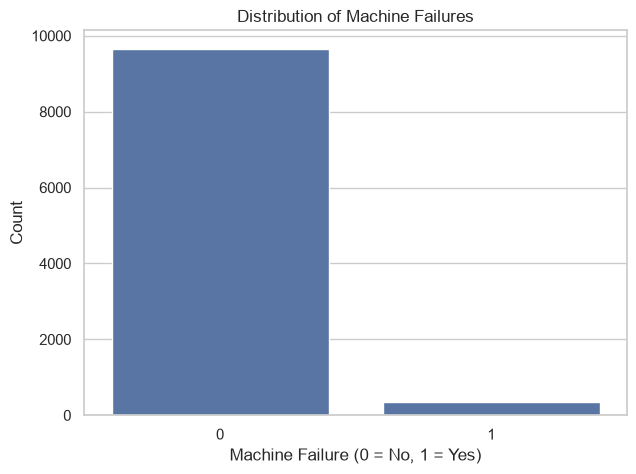

In [5]:
failure_counts = df["Machine failure"].value_counts()

failure_percent = (
    df["Machine failure"].value_counts(normalize=True) * 100
)

print("Failure counts:")
print(failure_counts)

print("\nFailure percentages:")
print(failure_percent.round(2))

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Distribution of Machine Failures")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

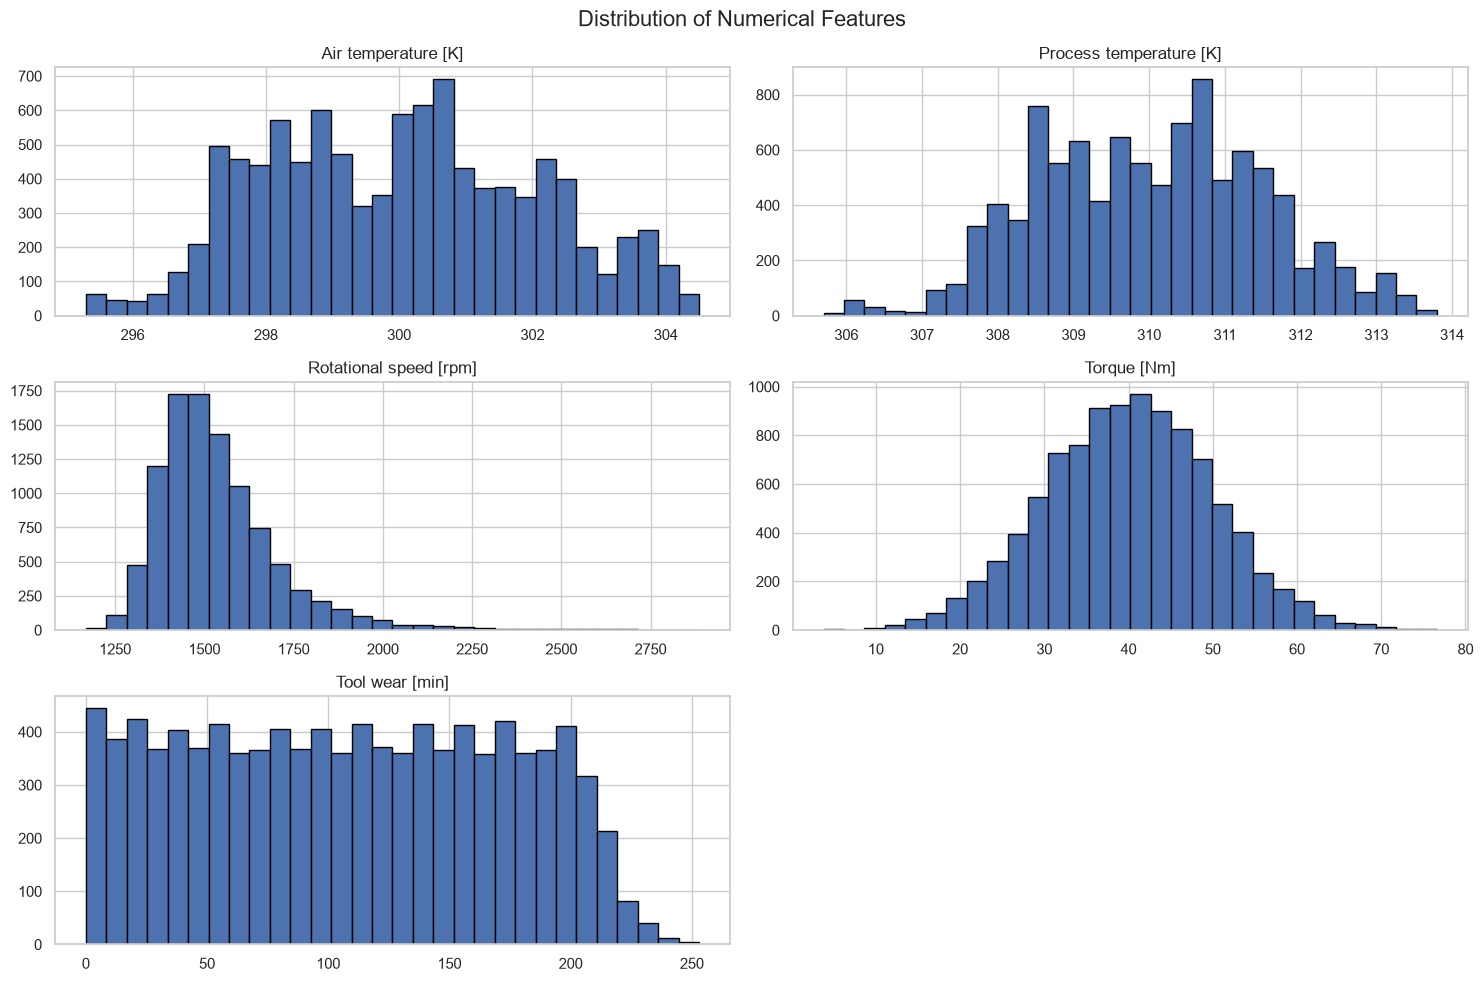

In [6]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[features].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

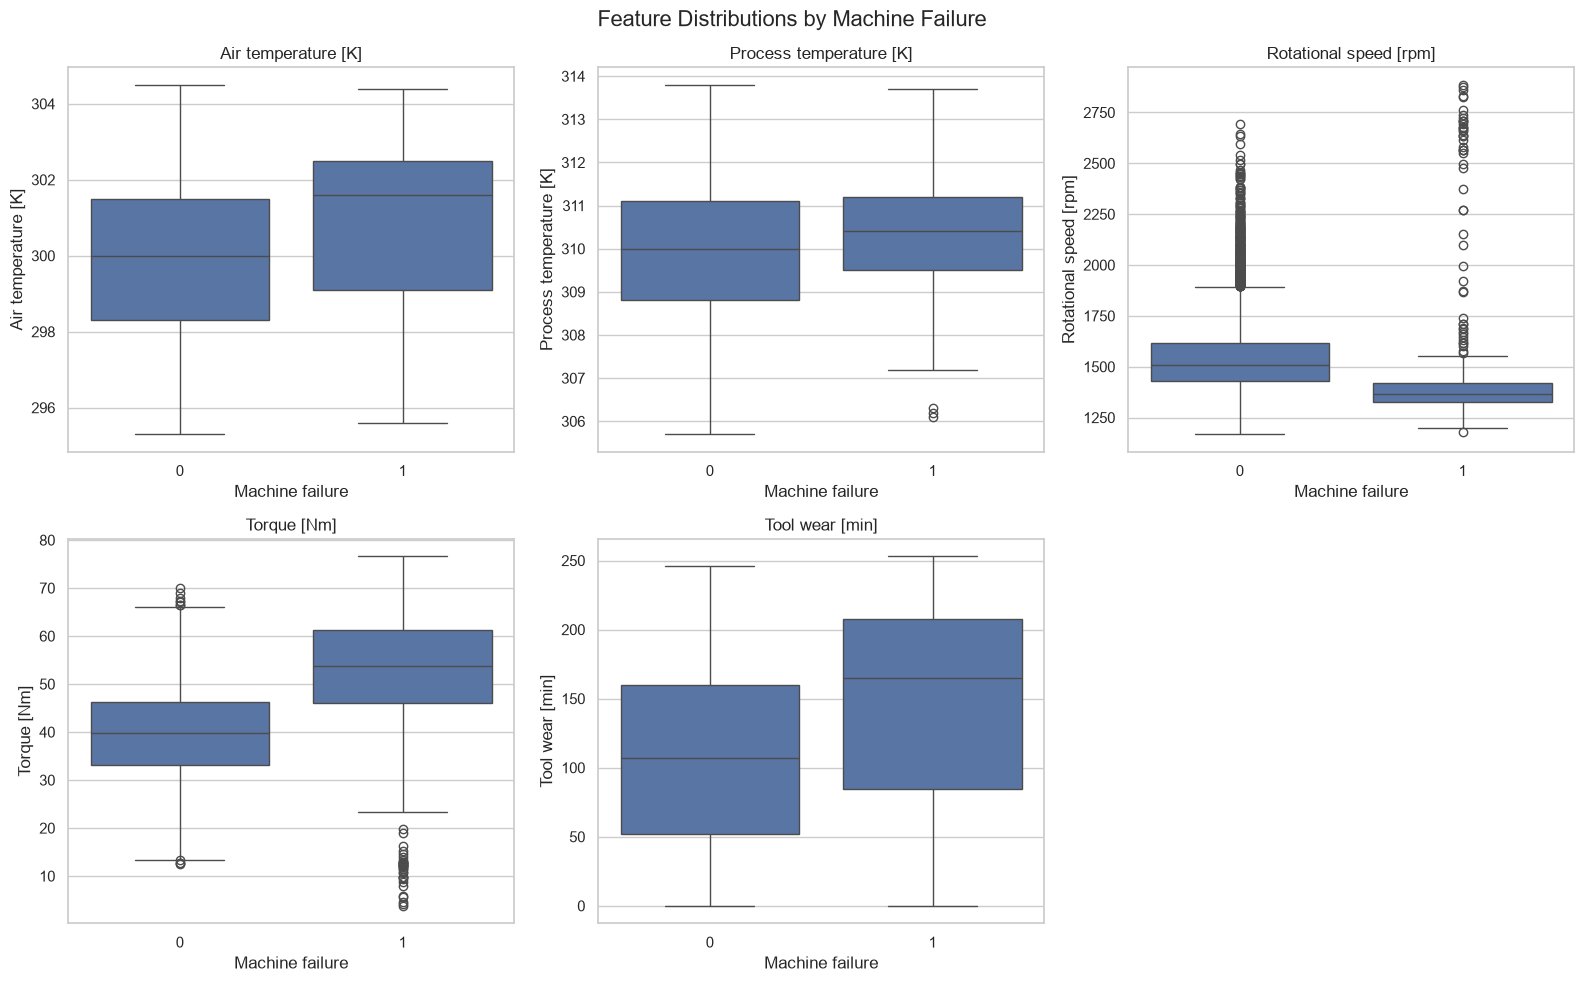

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)

for ax in axes.flat[len(features):]:
    ax.set_visible(False)

plt.suptitle(
    "Feature Distributions by Machine Failure",
    fontsize=16
)

plt.tight_layout()
plt.show()

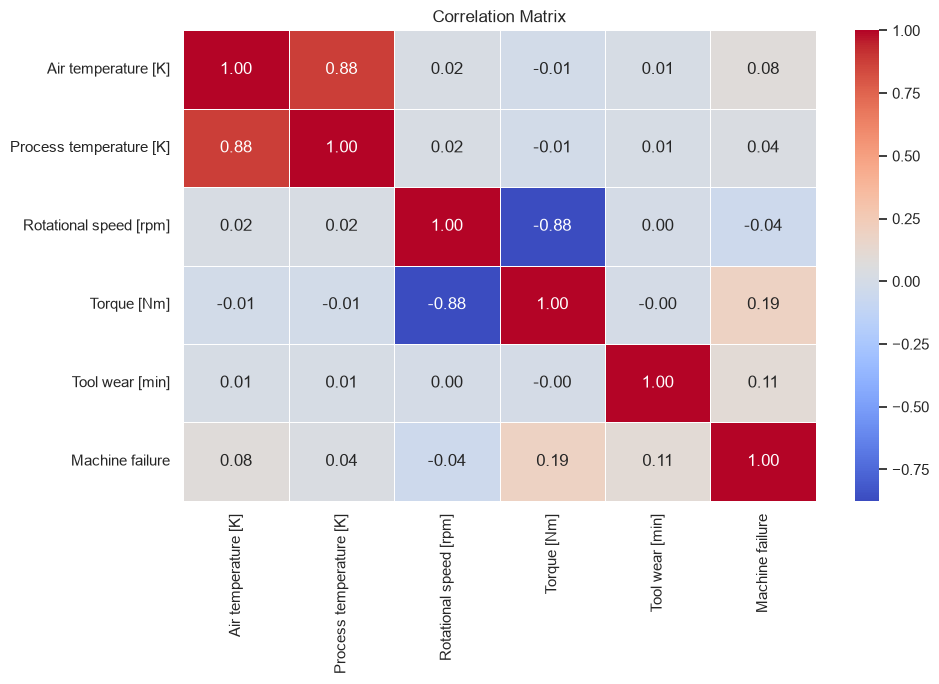

In [8]:
plt.figure(figsize=(10, 7))

corr = df[features + ["Machine failure"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

,count,sum,mean,failure_rate_%
Type,,,,
H,1003,21,0.020937,2.093719
L,6000,235,0.039167,3.916667
M,2997,83,0.027694,2.769436


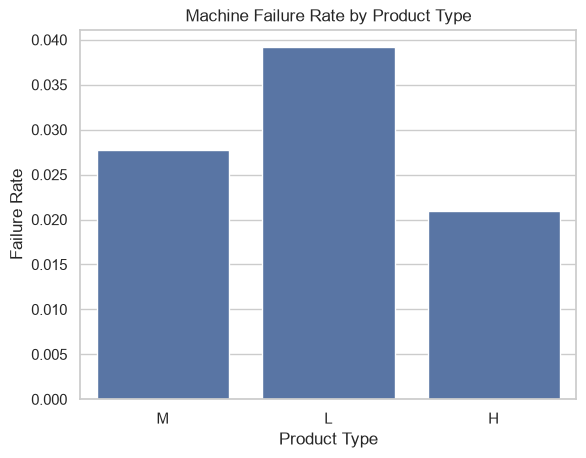

In [9]:
failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
)

failure_by_type["failure_rate_%"] = (
    failure_by_type["mean"] * 100
)

display(failure_by_type)

sns.barplot(
    data=df,
    x="Type",
    y="Machine failure",
    errorbar=None
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate")
plt.show()

## EDA Conclusions

The exploratory data analysis revealed several important findings:

1. The dataset contains 10,000 observations with no missing values or duplicate rows.
2. The target variable is highly imbalanced: only 3.39% of observations represent machine failures.
3. Failed machines tend to have higher torque, greater tool wear, and higher air temperature.
4. Rotational speed and torque show a strong negative correlation (-0.88).
5. Air temperature and process temperature are strongly positively correlated (0.88).
6. Product type L has the highest observed failure rate, followed by M and H.
7. Individual numerical features have relatively weak linear correlations with machine failure, suggesting that nonlinear relationships and feature interactions may be important.

**Modeling implications:**

- Use stratified train/test splitting to preserve the class distribution.
- Evaluate models using Precision, Recall, F1-score, and ROC-AUC rather than Accuracy alone.
- Exclude identifiers and failure-type indicators to prevent data leakage.
- Compare a Logistic Regression baseline with tree-based models.

In [10]:
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target_column = "Machine failure"

X = df[feature_columns].copy()
y = df[target_column].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [11]:
from sklearn.model_selection import train_test_split

# First split: 80% development, 20% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second split: 60% train, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (6000, 6)
Validation: (2000, 6)
Test: (2000, 6)


In [12]:
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    failure_rate = target.mean() * 100

    print(
        f"{name}: {len(target)} samples, "
        f"failure rate = {failure_rate:.2f}%"
    )

Train: 6000 samples, failure rate = 3.38%
Validation: 2000 samples, failure rate = 3.40%
Test: 2000 samples, failure rate = 3.40%


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


## Model Training

### Baseline: Logistic Regression

We start with Logistic Regression as a baseline model.
Since machine failures are rare, we use class_weight="balanced"
to account for class imbalance.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_reg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

log_reg_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_val_pred = log_reg_pipeline.predict(X_val)

y_val_proba = log_reg_pipeline.predict_proba(X_val)[:, 1]

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Accuracy: 0.8255
Precision: 0.1425
Recall: 0.8235
F1-score: 0.243
ROC-AUC: 0.8788

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.83      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.83      0.88      2000



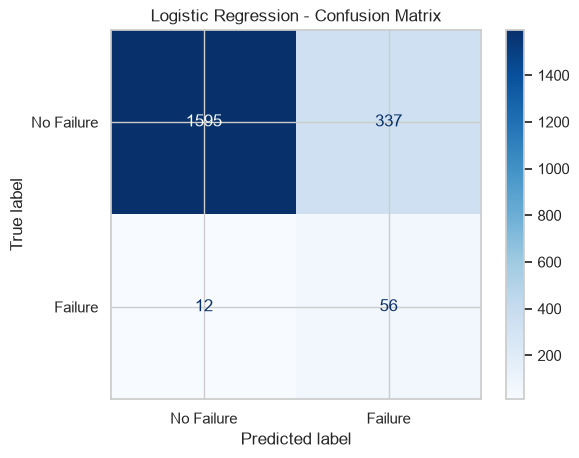

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines
multiple decision trees.

It can capture nonlinear relationships and interactions between
machine operating parameters.

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [18]:
rf_val_pred = rf_pipeline.predict(X_val)
rf_val_proba = rf_pipeline.predict_proba(X_val)[:, 1]

print("Random Forest Results")
print("-" * 30)

print("Accuracy:", round(accuracy_score(y_val, rf_val_pred), 4))
print("Precision:", round(precision_score(y_val, rf_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_val_pred), 4))
print("F1-score:", round(f1_score(y_val, rf_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_val_proba), 4))

print("\nClassification Report:")
print(classification_report(y_val, rf_val_pred, zero_division=0))

Random Forest Results
------------------------------
Accuracy: 0.963
Precision: 0.47
Recall: 0.6912
F1-score: 0.5595
ROC-AUC: 0.968

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.47      0.69      0.56        68

    accuracy                           0.96      2000
   macro avg       0.73      0.83      0.77      2000
weighted avg       0.97      0.96      0.97      2000



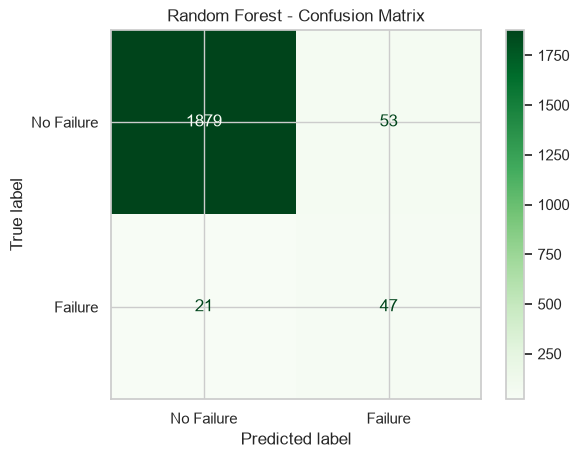

In [19]:
rf_cm = confusion_matrix(y_val, rf_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Greens", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.show()


### HistGradientBoosting Classifier

HistGradientBoosting is an ensemble learning algorithm that
builds decision trees sequentially.

Each new tree attempts to correct errors made by previous trees.

This model can capture nonlinear relationships between machine
operating parameters.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

hgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

hgb_pipeline.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

print("HistGradientBoosting trained successfully!")

HistGradientBoosting trained successfully!


In [21]:
hgb_val_pred = hgb_pipeline.predict(X_val)
hgb_val_proba = hgb_pipeline.predict_proba(X_val)[:, 1]

print("HistGradientBoosting Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_val, hgb_val_pred), 4))
print("Precision:", round(precision_score(y_val, hgb_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, hgb_val_pred), 4))
print("F1-score:", round(f1_score(y_val, hgb_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, hgb_val_proba), 4))

print("\nClassification Report:")
print(classification_report(y_val, hgb_val_pred, zero_division=0))

HistGradientBoosting Results
-----------------------------------
Accuracy: 0.9545
Precision: 0.4094
Recall: 0.7647
F1-score: 0.5333
ROC-AUC: 0.9748

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1932
           1       0.41      0.76      0.53        68

    accuracy                           0.95      2000
   macro avg       0.70      0.86      0.75      2000
weighted avg       0.97      0.95      0.96      2000



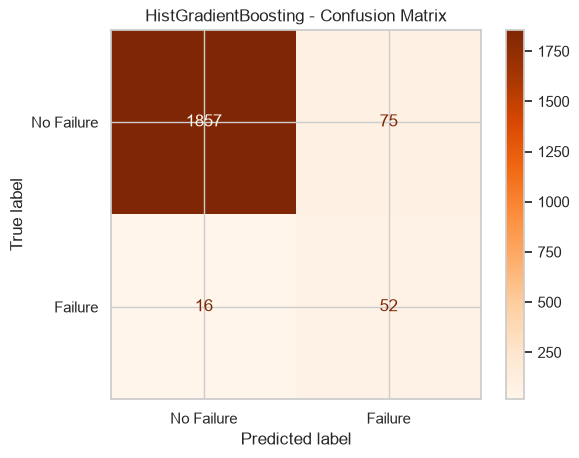

In [22]:
hgb_cm = confusion_matrix(y_val, hgb_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=hgb_cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Oranges", values_format="d")

plt.title("HistGradientBoosting - Confusion Matrix")
plt.show()

## Model Comparison

We compare three classification algorithms using the same
validation dataset.

Due to the significant class imbalance, we focus on Precision,
Recall, F1-score, ROC-AUC, and Average Precision (PR-AUC).

In [23]:
from sklearn.metrics import average_precision_score

models = {
    "Logistic Regression": log_reg_pipeline,
    "Random Forest": rf_pipeline,
    "HistGradientBoosting": hgb_pipeline
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_proba),
        "PR-AUC (AP)": average_precision_score(
            y_val, y_proba
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="PR-AUC (AP)",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC (AP)
2,HistGradientBoosting,0.9545,0.4094,0.7647,0.5333,0.9748,0.7137
1,Random Forest,0.9630,0.4700,0.6912,0.5595,0.9680,0.5555
0,Logistic Regression,0.8255,0.1425,0.8235,0.2430,0.8788,0.3680


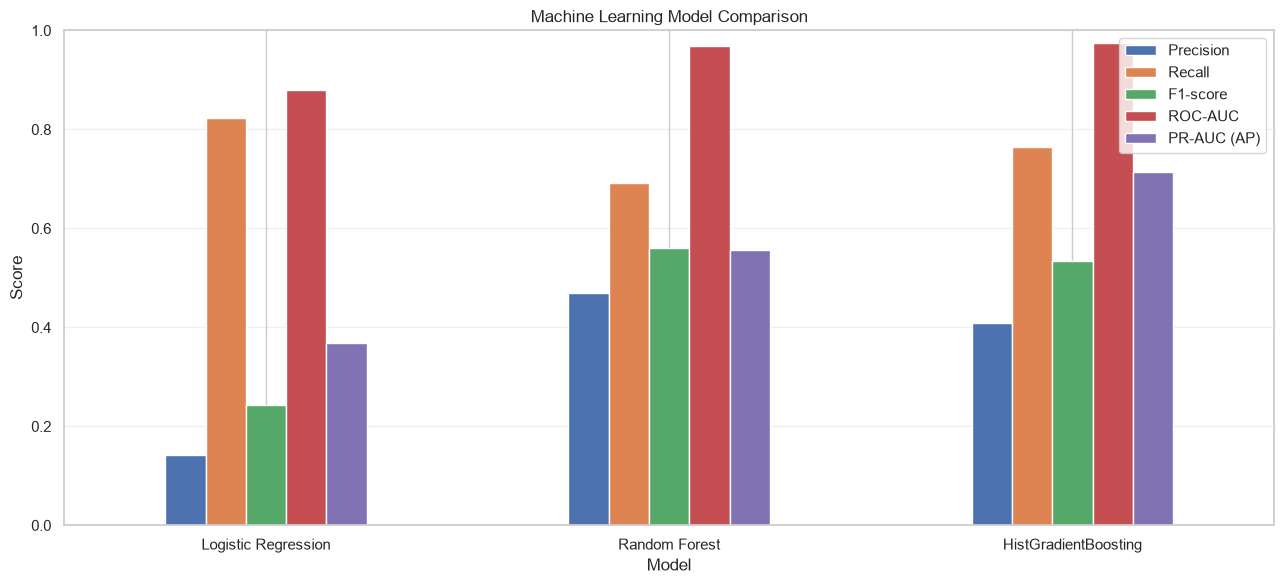

In [24]:
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC (AP)"
]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 6),
    rot=0
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Threshold Optimization

We optimize the classification threshold for HistGradientBoosting
using the validation dataset.

The goal is to improve the balance between Precision and Recall
while keeping the test dataset untouched.

In [25]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:
    predictions = (
        hgb_val_proba >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["F1-score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Best threshold:", round(best_threshold, 3))
print("Best F1-score:", round(best_row["F1-score"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))

Best threshold: 0.87
Best F1-score: 0.6667
Precision: 0.7455
Recall: 0.6029


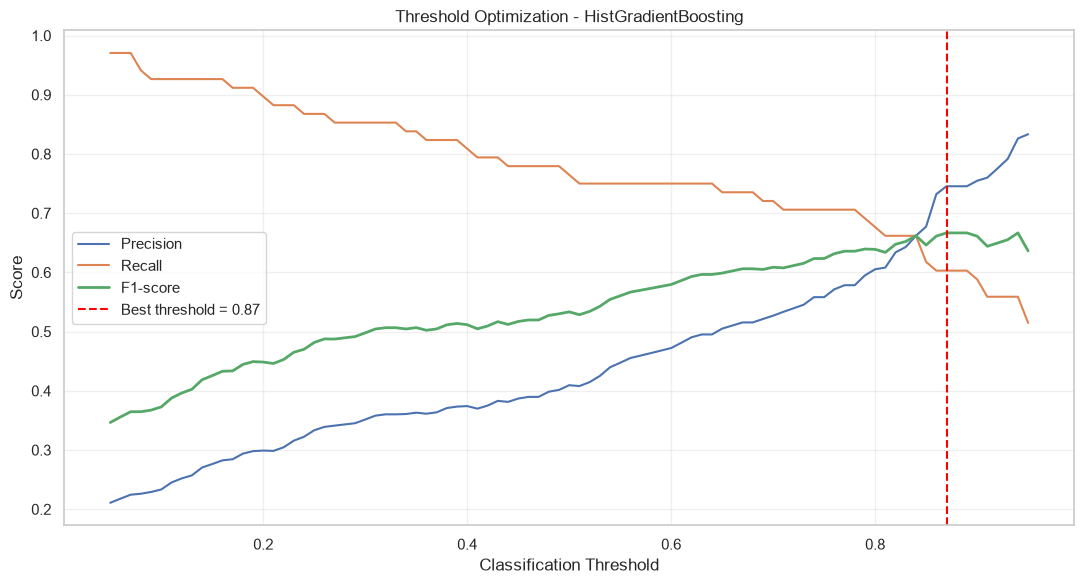

In [26]:
plt.figure(figsize=(11, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    label="F1-score",
    linewidth=2
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.title("Threshold Optimization - HistGradientBoosting")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

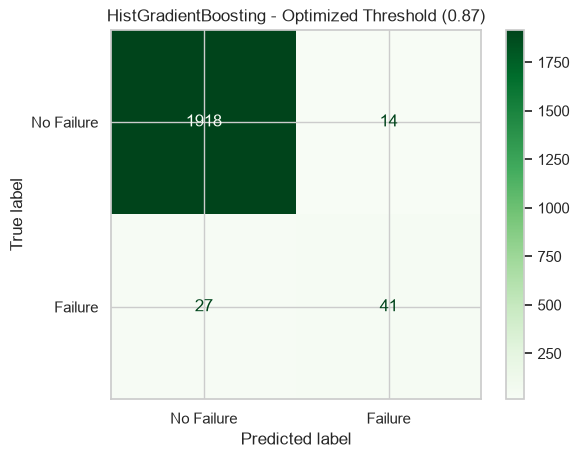

In [27]:
optimized_pred = (
    hgb_val_proba >= best_threshold
).astype(int)

optimized_cm = confusion_matrix(
    y_val,
    optimized_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=optimized_cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Greens", values_format="d")

plt.title(
    f"HistGradientBoosting - Optimized Threshold ({best_threshold:.2f})"
)

plt.show()

In [28]:
comparison = pd.DataFrame({
    "Configuration": [
        "Default threshold (0.5)",
        f"Optimized threshold ({best_threshold:.2f})"
    ],
    "Precision": [
        precision_score(y_val, hgb_val_pred),
        precision_score(y_val, optimized_pred)
    ],
    "Recall": [
        recall_score(y_val, hgb_val_pred),
        recall_score(y_val, optimized_pred)
    ],
    "F1-score": [
        f1_score(y_val, hgb_val_pred),
        f1_score(y_val, optimized_pred)
    ]
})

display(comparison.round(4))

,Configuration,Precision,Recall,F1-score
0,Default threshold (0.5),0.4094,0.7647,0.5333
1,Optimized threshold (0.87),0.7455,0.6029,0.6667


## Final Model Evaluation

HistGradientBoosting was selected based on validation performance.

The classification threshold was optimized to 0.87 using the
validation dataset.

We now retrain the model on the combined training and validation
datasets and evaluate it on the previously untouched test set.

In [29]:
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

final_model = clone(hgb_pipeline)

final_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_final_train
)

final_model.fit(
    X_final_train,
    y_final_train,
    classifier__sample_weight=final_weights
)

print("Final model trained successfully!")
print("Training samples:", len(X_final_train))

Final model trained successfully!
Training samples: 8000


In [30]:
from sklearn.metrics import average_precision_score

final_threshold = 0.87

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= final_threshold).astype(int)

print("Final Test Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred), 4))
print("F1-score:", round(f1_score(y_test, test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))
print("PR-AUC (AP):", round(average_precision_score(y_test, test_proba), 4))

Final Test Results
-----------------------------------
Accuracy: 0.9855
Precision: 0.8197
Recall: 0.7353
F1-score: 0.7752
ROC-AUC: 0.9753
PR-AUC (AP): 0.814


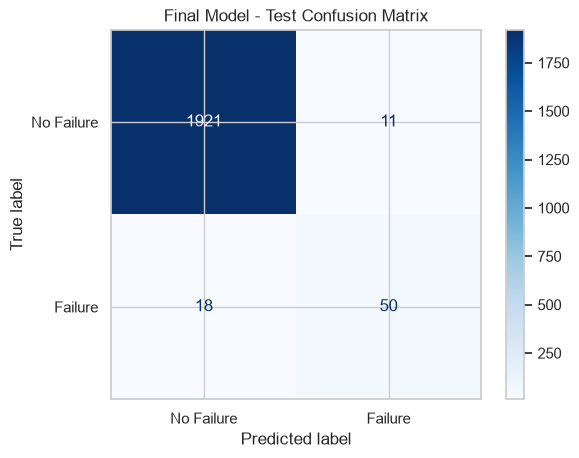

In [31]:
test_cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Final Model - Test Confusion Matrix")
plt.show()


## Final Model Results and Conclusions

Three machine learning algorithms were evaluated: Logistic Regression, Random Forest, and HistGradientBoosting.

HistGradientBoosting achieved the highest validation PR-AUC (0.7137) and was selected for threshold optimization.

The optimal validation threshold for F1-score was 0.87. The final model was retrained on the combined training and validation datasets and evaluated on the held-out test set.

### Final Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.9855 |
| Precision | 0.8197 |
| Recall | 0.7353 |
| F1-score | 0.7752 |
| ROC-AUC | 0.9753 |
| Average Precision | 0.8140 |

The model correctly detected 50 out of 68 machine failures, with 11 false alarms and 18 missed failures.

### Conclusion

HistGradientBoosting demonstrated strong classification performance on the synthetic AI4I 2020 dataset.

However, approximately 26.5% of failures were missed. Further validation, probability calibration, and cost-sensitive threshold selection would be necessary before real-world industrial deployment.